#Modelado Baseline
### Proyecto BIODIVERSITY-GUARD-Predict - Fase 4 de CRISP-DM: Modelado

Este notebook corresponde a la primera etapa de la Fase de Modelado: construcción y evaluación de modelos base (baseline) para ambos frentes, a partir de los datasets preparados en el Notebook 08 (`dataset_alertas_PREPARADO.csv`, `dataset_semanal_PREPARADO.csv`).

**Frente 1 (regresión):** se evaluan dos candidatos a baseline (Regresión Lineal y Árbol de Regresión), seleccionando el de mejor desempeño como punto de comparación para los modelos avanzados del Hito 3.

**Frente 2 (clasificación):** Árbol de Decisión, ya definido en el Business Understanding (sección 2.1.2) como baseline del frente.

**División temporal (train/test):** dado que ambos frentes trabajan con datos fechados de forma secuencial, la división en conjunto de entrenamiento y prueba se realiza de forma cronológica (no aleatoria), evitando que el modelo "vea" información del futuro durante el entrenamiento: train = 2022-01-01 a 2024-06-30; test = 2024-07-01 a 2024-12-31.

In [1]:
import pandas as pd
import numpy as np

df_alertas = pd.read_csv("dataset_alertas_PREPARADO.csv")
df_alertas["view_date"] = pd.to_datetime(df_alertas["view_date"])

df_semanal = pd.read_csv("dataset_semanal_PREPARADO.csv")
df_semanal["semana"] = pd.to_datetime(df_semanal["semana"])

print("dataset_alertas:", df_alertas.shape)
print("dataset_semanal:", df_semanal.shape)

dataset_alertas: (49971, 23)
dataset_semanal: (11445, 22)


## División temporal train/test

Split temporal, Frente 2

In [2]:
fecha_corte = "2024-07-01"

train_alertas = df_alertas[df_alertas["view_date"] < fecha_corte]
test_alertas = df_alertas[df_alertas["view_date"] >= fecha_corte]

print("Frente 2:")
print("Train:", train_alertas.shape, "-", train_alertas["view_date"].min(), "a", train_alertas["view_date"].max())
print("Test:", test_alertas.shape, "-", test_alertas["view_date"].min(), "a", test_alertas["view_date"].max())

print("\nDistribución de Nivel_Riesgo_Amenaza en train:")
print(train_alertas["Nivel_Riesgo_Amenaza"].value_counts(normalize=True).round(3))
print("\nDistribución de Nivel_Riesgo_Amenaza en test:")
print(test_alertas["Nivel_Riesgo_Amenaza"].value_counts(normalize=True).round(3))

Frente 2:
Train: (30625, 23) - 2022-01-01 00:00:00 a 2024-06-30 00:00:00
Test: (19346, 23) - 2024-07-01 00:00:00 a 2024-12-31 00:00:00

Distribución de Nivel_Riesgo_Amenaza en train:
Nivel_Riesgo_Amenaza
Moderado    0.646
Alto        0.198
Bajo        0.086
Crítico     0.071
Name: proportion, dtype: float64

Distribución de Nivel_Riesgo_Amenaza en test:
Nivel_Riesgo_Amenaza
Moderado    0.654
Bajo        0.199
Alto        0.088
Crítico     0.059
Name: proportion, dtype: float64


Split temporal, Frente 1

In [3]:
train_semanal = df_semanal[df_semanal["semana"] < fecha_corte]
test_semanal = df_semanal[df_semanal["semana"] >= fecha_corte]

print("Frente 1:")
print("Train:", train_semanal.shape, "-", train_semanal["semana"].min(), "a", train_semanal["semana"].max())
print("Test:", test_semanal.shape, "-", test_semanal["semana"].min(), "a", test_semanal["semana"].max())

Frente 1:
Train: (8719, 22) - 2021-12-27 00:00:00 a 2024-06-24 00:00:00
Test: (2726, 22) - 2024-07-01 00:00:00 a 2024-12-30 00:00:00


In [4]:
print("Frente 2 (dataset_alertas):")
total_alertas = len(df_alertas)
print(f"Train: {len(train_alertas)} filas ({len(train_alertas)/total_alertas*100:.1f}%)")
print(f"Test:  {len(test_alertas)} filas ({len(test_alertas)/total_alertas*100:.1f}%)")

print("\nFrente 1 (dataset_semanal):")
total_semanal = len(df_semanal)
print(f"Train: {len(train_semanal)} filas ({len(train_semanal)/total_semanal*100:.1f}%)")
print(f"Test:  {len(test_semanal)} filas ({len(test_semanal)/total_semanal*100:.1f}%)")

Frente 2 (dataset_alertas):
Train: 30625 filas (61.3%)
Test:  19346 filas (38.7%)

Frente 1 (dataset_semanal):
Train: 8719 filas (76.2%)
Test:  2726 filas (23.8%)


### Hallazgo: distribución de clases entre train y test

La clase "Moderado" mantiene una proporción estable entre train (64.6%) y test (65.4%). Sin embargo, "Alto" y "Bajo" muestran una inversión notable: Alto pasa de 19.8% (train) a 8.8% (test), mientras Bajo pasa de 8.6% a 19.9%. Esto es consistente con el cambio de composición de `classname` documentado en el EDA para el periodo de julio-diciembre 2024 (mayor predominancia de `CICATRIZ_DE_QUEIMADA`, de severidad baja en la fórmula de `score_riesgo`, asociada a la temporada de incendios extrema de ese año), en contraste con una mayor proporción de amenazas de severidad intermedia en el periodo de entrenamiento. Esta diferencia de distribución entre train y test se documenta como un desafío esperado para el modelo de clasificación, y se tendrá en cuenta al interpretar sus métricas por clase.

## Modelo Baseline - Frente 2 (Clasificación): Árbol de Decisión

Se entrena un árbol de decisión simple como modelo base, evaluado con las métricas priorizadas por el curso: precision, recall, F1-score (macro) y matriz de confusión. Dado el desbalance de clases ya documentado (Moderado concentra ~65% de las observaciones), se prioriza F1-score macro sobre accuracy, con atención especial al recall de la clase "Crítico" (ver criterios de éxito técnico, sección 2.1.2).

In [5]:
features_alertas_final = ['lat', 'lon', 'frp_total_7d_previo', 'precipitacion_promedio_7d_previo',
                           'dias_sin_lluvia_promedio_7d_previo', 'riesgo_fuego_promedio_7d_previo',
                           'pm2_5_reanalise_7d_previo', 'o3_reanalise_7d_previo', 'no2_reanalise_7d_previo',
                           'T2M_7d_previo', 'RH2M_7d_previo', 'WS2M_7d_previo',
                           'precipitacion_promedio_7d_previo_sin_foco',
                           'dias_sin_lluvia_promedio_7d_previo_sin_foco',
                           'riesgo_fuego_promedio_7d_previo_sin_foco']

print("Total features Frente 2:", len(features_alertas_final))

faltantes = [c for c in features_alertas_final if c not in df_alertas.columns]
print("Features faltantes en el dataset:", faltantes)

Total features Frente 2: 15
Features faltantes en el dataset: []


In [6]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

X_train_alertas = train_alertas[features_alertas_final]
y_train_alertas = train_alertas["Nivel_Riesgo_Amenaza"]

X_test_alertas = test_alertas[features_alertas_final]
y_test_alertas = test_alertas["Nivel_Riesgo_Amenaza"]

print("X_train:", X_train_alertas.shape, "| y_train:", y_train_alertas.shape)
print("X_test:", X_test_alertas.shape, "| y_test:", y_test_alertas.shape)

X_train: (30625, 15) | y_train: (30625,)
X_test: (19346, 15) | y_test: (19346,)


In [7]:
modelo_arbol = DecisionTreeClassifier(random_state=42, max_depth=10)
modelo_arbol.fit(X_train_alertas, y_train_alertas)

y_pred_train = modelo_arbol.predict(X_train_alertas)
y_pred_test = modelo_arbol.predict(X_test_alertas)

print("Modelo entrenado.")
print("Profundidad del árbol:", modelo_arbol.get_depth())
print("Número de hojas:", modelo_arbol.get_n_leaves())

Modelo entrenado.
Profundidad del árbol: 10
Número de hojas: 715


In [8]:
print("=== Reporte de clasificación - TRAIN ===")
print(classification_report(y_train_alertas, y_pred_train))

print("\n=== Reporte de clasificación - TEST ===")
print(classification_report(y_test_alertas, y_pred_test))

f1_train = f1_score(y_train_alertas, y_pred_train, average="macro")
f1_test = f1_score(y_test_alertas, y_pred_test, average="macro")
print(f"\nF1 macro - Train: {f1_train:.3f} | Test: {f1_test:.3f}")
print(f"Brecha train-test: {f1_train - f1_test:.3f}")

=== Reporte de clasificación - TRAIN ===
              precision    recall  f1-score   support

        Alto       0.59      0.21      0.31      6050
        Bajo       0.70      0.16      0.26      2625
     Crítico       0.59      0.19      0.29      2168
    Moderado       0.70      0.96      0.81     19782

    accuracy                           0.69     30625
   macro avg       0.64      0.38      0.42     30625
weighted avg       0.67      0.69      0.63     30625


=== Reporte de clasificación - TEST ===
              precision    recall  f1-score   support

        Alto       0.11      0.07      0.09      1693
        Bajo       0.23      0.06      0.10      3858
     Crítico       0.20      0.11      0.14      1137
    Moderado       0.66      0.87      0.75     12658

    accuracy                           0.60     19346
   macro avg       0.30      0.28      0.27     19346
weighted avg       0.50      0.60      0.53     19346


F1 macro - Train: 0.418 | Test: 0.270
Brecha tr

In [9]:
modelo_balanceado = DecisionTreeClassifier(max_depth=10, random_state=42, class_weight="balanced")
modelo_balanceado.fit(X_train_alertas, y_train_alertas)

y_pred_train_bal = modelo_balanceado.predict(X_train_alertas)
y_pred_test_bal = modelo_balanceado.predict(X_test_alertas)

print("=== TRAIN (balanceado) ===")
print(classification_report(y_train_alertas, y_pred_train_bal))
print("\n=== TEST (balanceado) ===")
print(classification_report(y_test_alertas, y_pred_test_bal))

print(f"\nF1 macro - Train: {f1_score(y_train_alertas, y_pred_train_bal, average='macro'):.3f}")
print(f"F1 macro - Test: {f1_score(y_test_alertas, y_pred_test_bal, average='macro'):.3f}")

=== TRAIN (balanceado) ===
              precision    recall  f1-score   support

        Alto       0.33      0.44      0.38      6050
        Bajo       0.23      0.78      0.35      2625
     Crítico       0.24      0.69      0.36      2168
    Moderado       0.83      0.31      0.45     19782

    accuracy                           0.40     30625
   macro avg       0.41      0.56      0.39     30625
weighted avg       0.64      0.40      0.42     30625


=== TEST (balanceado) ===
              precision    recall  f1-score   support

        Alto       0.13      0.14      0.14      1693
        Bajo       0.21      0.67      0.32      3858
     Crítico       0.08      0.18      0.11      1137
    Moderado       0.69      0.15      0.25     12658

    accuracy                           0.26     19346
   macro avg       0.28      0.29      0.21     19346
weighted avg       0.51      0.26      0.25     19346


F1 macro - Train: 0.386
F1 macro - Test: 0.207


In [10]:
resultados_profundidad = []

for profundidad in [3, 5, 8, 10, 15, None]:
    modelo_prueba = DecisionTreeClassifier(max_depth=profundidad, random_state=42)
    modelo_prueba.fit(X_train_alertas, y_train_alertas)

    f1_train = f1_score(y_train_alertas, modelo_prueba.predict(X_train_alertas), average="macro")
    f1_test = f1_score(y_test_alertas, modelo_prueba.predict(X_test_alertas), average="macro")

    resultados_profundidad.append({"max_depth": profundidad, "f1_train": round(f1_train,3),
                                     "f1_test": round(f1_test,3), "brecha": round(f1_train-f1_test,3)})

pd.DataFrame(resultados_profundidad)

,max_depth,f1_train,f1_test,brecha
0,3.0,0.196,0.198,-0.002
1,5.0,0.211,0.198,0.013
2,8.0,0.299,0.223,0.076
3,10.0,0.418,0.270,0.148
4,15.0,0.695,0.274,0.421
5,NaN,1.000,0.275,0.725


### Hallazgo: techo de desempeño independiente de la profundidad del árbol

Se evaluaron 6 valores de profundidad máxima (3, 5, 8, 10, 15, sin límite). El F1 macro en entrenamiento aumenta de forma monótona hasta alcanzar 1.000 (memorización completa) con el árbol sin restricción, mientras que el F1 macro en prueba se estabiliza entre 0.198 y 0.275 sin importar la profundidad, evidenciando que el límite de desempeño no está determinado por la complejidad del modelo, sino por el poder discriminante limitado de las variables predictoras disponibles (todas de origen climático, tras la exclusión de variables con fuga de información). Se seleccionó max_depth=8 como configuración del baseline, al ofrecer la mejor relación entre desempeño en prueba (F1 macro 0.223) y brecha de generalización (0.076), evitando el sobreajuste severo observado en profundidades mayores.

=== Reporte TEST (baseline final, max_depth=8) ===
              precision    recall  f1-score   support

        Alto       0.19      0.04      0.07      1693
        Bajo       0.23      0.02      0.03      3858
     Crítico       0.10      0.01      0.01      1137
    Moderado       0.66      0.96      0.78     12658

    accuracy                           0.64     19346
   macro avg       0.29      0.26      0.22     19346
weighted avg       0.50      0.64      0.52     19346



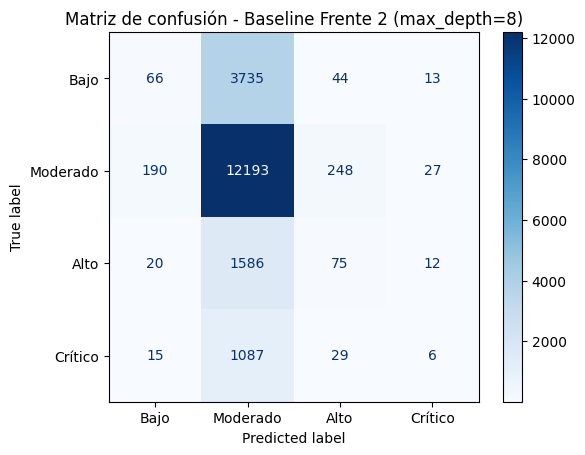

In [11]:
modelo_arbol_final = DecisionTreeClassifier(max_depth=8, random_state=42)
modelo_arbol_final.fit(X_train_alertas, y_train_alertas)

y_pred_train_final = modelo_arbol_final.predict(X_train_alertas)
y_pred_test_final = modelo_arbol_final.predict(X_test_alertas)

print("=== Reporte TEST (baseline final, max_depth=8) ===")
print(classification_report(y_test_alertas, y_pred_test_final))

cm = confusion_matrix(y_test_alertas, y_pred_test_final, labels=["Bajo", "Moderado", "Alto", "Crítico"])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Bajo", "Moderado", "Alto", "Crítico"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - Baseline Frente 2 (max_depth=8)")
plt.show()

### Conclusión: Baseline Frente 2 (Árbol de Decisión, max_depth=8)

El modelo baseline alcanza un accuracy global de 0.64, cifra que resulta engañosa dado el desbalance de clases: la matriz de confusión evidencia que el modelo predice "Moderado" para la gran mayoría de las observaciones, independientemente de su clase real (97% de los casos reales de "Bajo", 94% de "Alto" y 96% de "Crítico" fueron clasificados erróneamente como "Moderado"). El F1-score macro de 0.22 y el recall prácticamente nulo en las clases "Alto" (0.04), "Bajo" (0.02) y "Crítico" (0.01) confirman que el modelo no logra discriminar el nivel de riesgo real a partir de las variables climáticas disponibles.

Este resultado es consistente con los hallazgos previos del proyecto: las correlaciones entre variables climáticas y los indicadores de riesgo documentadas en el EDA (Hito 1) fueron débiles en todos los casos (r < 0.20), y la prueba de sensibilidad a la profundidad del árbol (ver hallazgo anterior) mostró que el desempeño en prueba se estabiliza independientemente de la complejidad del modelo. Se concluye que un árbol de decisión simple constituye un punto de referencia necesario pero insuficiente para la tarea, y se espera que modelos con mayor capacidad de capturar relaciones no lineales e interacciones entre variables (Random Forest, XGBoost), previstos para el Hito 3, mejoren sustancialmente la capacidad de discriminación, particularmente en las clases de mayor relevancia operativa (Alto y Crítico).

**Nota metodológica:** se evaluó adicionalmente la técnica de ponderación de clases (class_weight='balanced'), obteniendo un desempeño inferior (F1 macro de 0.207 en prueba, frente a 0.270 del modelo sin ponderar con max_depth=10), lo que sugiere que el desbalance de clases no es, por sí solo, la causa principal de la baja capacidad discriminativa del modelo, sino la limitada señal predictiva disponible en el conjunto de variables climáticas tras la exclusión de variables con fuga de información.

## Modelo Baseline - Frente 1 (Regresión): comparación de candidatos

Se evalúan dos candidatos a modelo base: Regresión Lineal y Árbol de Regresión, seleccionando el de mejor desempeño como baseline oficial del frente, evaluado con MAE, RMSE y R² sobre el conjunto de prueba, de acuerdo con los criterios de éxito técnico definidos en la sección 2.1.2 (MAE ≤ 20 ha a 7 días, equivalente al horizonte semanal de este dataset).

In [12]:
features_semanal_final = ['num_incendios', 'frp_promedio', 'precipitacion_promedio',
                           'dias_sin_lluvia_promedio', 'riesgo_fuego_promedio', 'pm2_5_reanalise',
                           'o3_reanalise', 'no2_reanalise', 'so2_reanalise', 'T2M', 'RH2M', 'WS2M',
                           'lat', 'lon', 'precipitacion_promedio_sin_foco',
                           'dias_sin_lluvia_promedio_sin_foco', 'riesgo_fuego_promedio_sin_foco']

print("Total features Frente 1:", len(features_semanal_final))
faltantes = [c for c in features_semanal_final if c not in df_semanal.columns]
print("Features faltantes:", faltantes)

Total features Frente 1: 17
Features faltantes: []


In [13]:
X_train_semanal = train_semanal[features_semanal_final]
y_train_semanal = train_semanal["area_ha_total_log"]

X_test_semanal = test_semanal[features_semanal_final]
y_test_semanal = test_semanal["area_ha_total_log"]

print("X_train:", X_train_semanal.shape, "| y_train:", y_train_semanal.shape)
print("X_test:", X_test_semanal.shape, "| y_test:", y_test_semanal.shape)

X_train: (8719, 17) | y_train: (8719,)
X_test: (2726, 17) | y_test: (2726,)


**Entrenar Regresión Lineal**

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train_semanal, y_train_semanal)

pred_train_lineal = modelo_lineal.predict(X_train_semanal)
pred_test_lineal = modelo_lineal.predict(X_test_semanal)

**Entrenar Árbol de Regresión**

In [15]:
modelo_arbol_reg = DecisionTreeRegressor(max_depth=8, random_state=42)
modelo_arbol_reg.fit(X_train_semanal, y_train_semanal)

pred_train_arbol = modelo_arbol_reg.predict(X_train_semanal)
pred_test_arbol = modelo_arbol_reg.predict(X_test_semanal)

In [16]:
def evaluar_modelo(nombre, y_true_log, y_pred_log):

    mae_log = mean_absolute_error(y_true_log, y_pred_log)
    rmse_log = np.sqrt(mean_squared_error(y_true_log, y_pred_log))
    r2 = r2_score(y_true_log, y_pred_log)


    y_true_ha = np.expm1(y_true_log)
    y_pred_ha = np.expm1(y_pred_log)
    mae_ha = mean_absolute_error(y_true_ha, y_pred_ha)
    rmse_ha = np.sqrt(mean_squared_error(y_true_ha, y_pred_ha))

    return {"modelo": nombre, "MAE_log": round(mae_log,3), "RMSE_log": round(rmse_log,3),
            "R2": round(r2,3), "MAE_hectareas": round(mae_ha,2), "RMSE_hectareas": round(rmse_ha,2)}

resultados = []
resultados.append(evaluar_modelo("Regresión Lineal - Train", y_train_semanal, pred_train_lineal))
resultados.append(evaluar_modelo("Regresión Lineal - Test", y_test_semanal, pred_test_lineal))
resultados.append(evaluar_modelo("Árbol de Regresión - Train", y_train_semanal, pred_train_arbol))
resultados.append(evaluar_modelo("Árbol de Regresión - Test", y_test_semanal, pred_test_arbol))

pd.DataFrame(resultados)

,modelo,MAE_log,RMSE_log,R2,MAE_hectareas,RMSE_hectareas
0,Regresión Lineal - Train,1.114,1.379,0.112,173.22,679.16
1,Regresión Lineal - Test,1.375,1.732,0.069,567.34,2215.69
2,Árbol de Regresión - Train,0.948,1.206,0.321,151.19,595.70
3,Árbol de Regresión - Test,1.421,1.831,-0.040,575.81,2179.95


### Hallazgo: comparación de candidatos a baseline (Frente 1)

El Árbol de Regresión superó a la Regresión Lineal en el conjunto de entrenamiento (R²=0.321 vs 0.112), pero mostró un colapso severo en el conjunto de prueba (R²=-0.040, peor que predecir la media), mientras que la Regresión Lineal mantuvo un desempeño positivo aunque modesto (R²=0.069). Este patrón es consistente con dos factores ya documentados en el proyecto: (1) las variables climáticas disponibles muestran correlaciones débiles con el área afectada (máximo r=0.29 en el EDA), y (2) el conjunto de prueba corresponde al periodo de julio-diciembre de 2024, un semestre atípico por la escalada histórica de incendios, sobre el cual el árbol —más propenso a sobreajustar patrones específicos del periodo de entrenamiento— generaliza peor que un modelo lineal más simple y estable.

**Se selecciona la Regresión Lineal como baseline oficial del Frente 1**, por ofrecer un desempeño más consistente entre entrenamiento y prueba, pese a su capacidad predictiva limitada en términos absolutos.

**Nota sobre el criterio de éxito:** el MAE obtenido (567.34 ha en escala real) se encuentra muy por encima del umbral de éxito definido (≤20 ha), resultado esperado para un modelo base sin ajuste de hiperparámetros, sin construcción de variables rezagadas (lags) y sin selección de un algoritmo con mayor capacidad de captura de relaciones no lineales. Este resultado delimita el punto de partida sobre el cual se medirá la mejora de los modelos avanzados en el Hito 3.

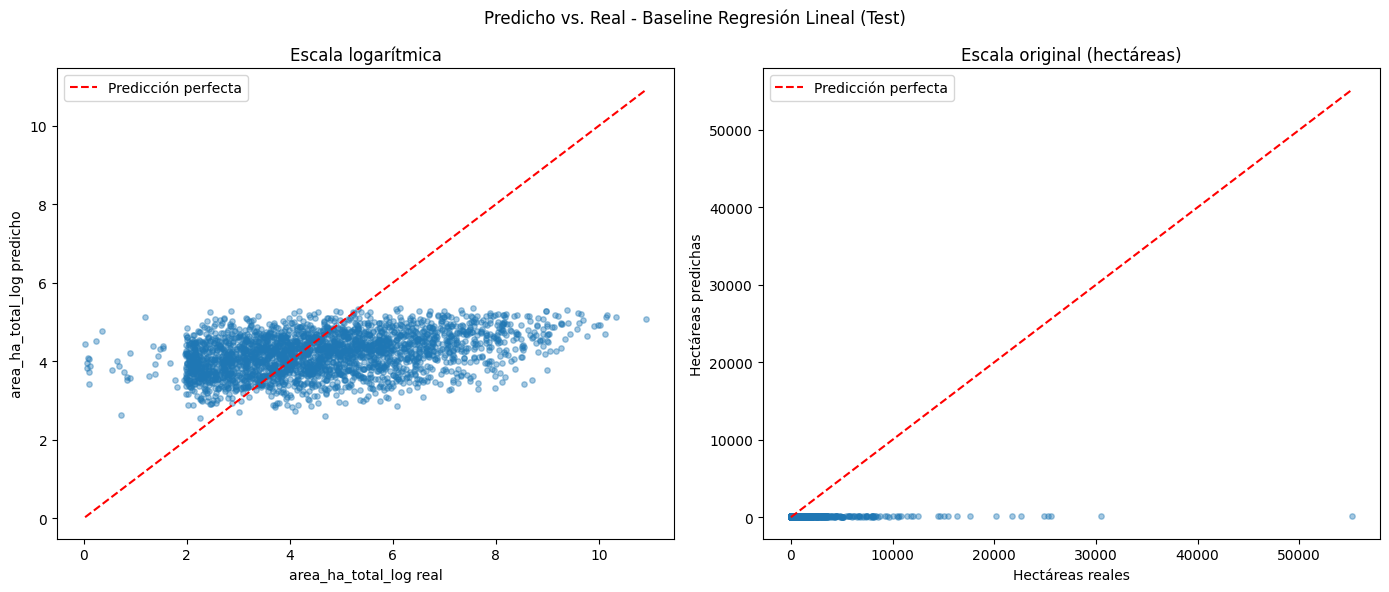

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Panel 1: en escala log (la que usa el modelo internamente)
axes[0].scatter(y_test_semanal, pred_test_lineal, alpha=0.4, s=15)
lims = [min(y_test_semanal.min(), pred_test_lineal.min()), max(y_test_semanal.max(), pred_test_lineal.max())]
axes[0].plot(lims, lims, color="red", linestyle="--", label="Predicción perfecta")
axes[0].set_xlabel("area_ha_total_log real")
axes[0].set_ylabel("area_ha_total_log predicho")
axes[0].set_title("Escala logarítmica")
axes[0].legend()

# Panel 2: en hectáreas reales (revirtiendo la transformación)
y_test_ha = np.expm1(y_test_semanal)
pred_test_ha = np.expm1(pred_test_lineal)

axes[1].scatter(y_test_ha, pred_test_ha, alpha=0.4, s=15)
lims_ha = [0, max(y_test_ha.max(), pred_test_ha.max())]
axes[1].plot(lims_ha, lims_ha, color="red", linestyle="--", label="Predicción perfecta")
axes[1].set_xlabel("Hectáreas reales")
axes[1].set_ylabel("Hectáreas predichas")
axes[1].set_title("Escala original (hectáreas)")
axes[1].legend()

plt.suptitle("Predicho vs. Real - Baseline Regresión Lineal (Test)")
plt.tight_layout()
plt.show()

### Hallazgo: el modelo subestima sistemáticamente los eventos de gran magnitud

La comparación entre valores predichos y reales confirma visualmente la limitación ya anticipada por las métricas: el modelo predice un rango estrecho de valores (aproximadamente 3 a 5.5 en escala logarítmica, equivalente a decenas o cientos de hectáreas) independientemente de la magnitud real del evento, que en el conjunto de prueba alcanza hasta 55,192 hectáreas en una sola semana-municipio. Esta subestimación sistemática de los eventos extremos es consistente con el carácter atípico del periodo de prueba (julio-diciembre 2024, correspondiente a la escalada de incendios documentada en el EDA) y con la débil relación lineal entre las variables climáticas disponibles y el área afectada.

**Implicación para el negocio:** el baseline resulta insuficiente precisamente para el caso de uso más crítico del proyecto —anticipar eventos de deforestación de gran escala—, mientras que su desempeño podría ser más razonable para la mayoría de semanas de magnitud baja o moderada,

## Resumen consolidado de métricas - Modelado Baseline

tabla consolidada, Frente 1

In [18]:
resumen_frente1 = pd.DataFrame([
    {"Modelo": "Regresión Lineal", "Conjunto": "Train", "R2": 0.112, "MAE_ha": 173.22, "RMSE_ha": 679.16},
    {"Modelo": "Regresión Lineal", "Conjunto": "Test", "R2": 0.069, "MAE_ha": 567.34, "RMSE_ha": 2215.69},
    {"Modelo": "Árbol de Regresión", "Conjunto": "Train", "R2": 0.321, "MAE_ha": 151.19, "RMSE_ha": 595.70},
    {"Modelo": "Árbol de Regresión", "Conjunto": "Test", "R2": -0.040, "MAE_ha": 575.81, "RMSE_ha": 2179.95},
])

print("=== Frente 1 (Regresión) - Resumen de métricas ===")
resumen_frente1

=== Frente 1 (Regresión) - Resumen de métricas ===


,Modelo,Conjunto,R2,MAE_ha,RMSE_ha
0,Regresión Lineal,Train,0.112,173.22,679.16
1,Regresión Lineal,Test,0.069,567.34,2215.69
2,Árbol de Regresión,Train,0.321,151.19,595.70
3,Árbol de Regresión,Test,-0.040,575.81,2179.95


Tabla consolidada, Frente 2

In [19]:
resumen_frente2 = pd.DataFrame([
    {"Clase": "Bajo", "Precision": 0.23, "Recall": 0.02, "F1": 0.03, "Support": 3858},
    {"Clase": "Moderado", "Precision": 0.66, "Recall": 0.96, "F1": 0.78, "Support": 12658},
    {"Clase": "Alto", "Precision": 0.19, "Recall": 0.04, "F1": 0.07, "Support": 1693},
    {"Clase": "Crítico", "Precision": 0.10, "Recall": 0.01, "F1": 0.01, "Support": 1137},
])

print("=== Frente 2 (Clasificación, Árbol de Decisión, Test) - Resumen por clase ===")
print(f"\nAccuracy global: 0.64")
print(f"F1-score macro: 0.22")
print(f"F1-score weighted: 0.52")
resumen_frente2


=== Frente 2 (Clasificación, Árbol de Decisión, Test) - Resumen por clase ===

Accuracy global: 0.64
F1-score macro: 0.22
F1-score weighted: 0.52


,Clase,Precision,Recall,F1,Support
0,Bajo,0.23,0.02,0.03,3858
1,Moderado,0.66,0.96,0.78,12658
2,Alto,0.19,0.04,0.07,1693
3,Crítico,0.10,0.01,0.01,1137


## Exportación de predicciones para el Dashboard (Streamlit)

Se generan y exportan los datasets de predicciones de ambos frentes (conjunto de prueba), que servirán de insumo al dashboard preliminar, sin necesidad de reentrenar el modelo dentro de la app.

In [20]:
df_original = pd.read_csv("dataset_alertas_COMPLETO.csv")

coords_por_alerta = df_original[["id_alerta", "lat", "lon"]].rename(
    columns={"lat": "lat_real", "lon": "lon_real"})

coords_por_municipio = df_original.groupby(["municipio_norm", "uf"])[["lat", "lon"]].mean().reset_index()
coords_por_municipio = coords_por_municipio.rename(columns={"lat": "lat_real", "lon": "lon_real"})

print("Coordenadas por alerta:", coords_por_alerta.shape)
print("Coordenadas por municipio:", coords_por_municipio.shape)

Coordenadas por alerta: (49971, 3)
Coordenadas por municipio: (425, 4)


In [21]:
predicciones_frente1 = test_semanal[["semana", "municipio_norm", "uf", "area_ha_total"]].copy()
predicciones_frente1["area_ha_total_predicha"] = np.expm1(pred_test_lineal)
predicciones_frente1["area_ha_total_predicha"] = predicciones_frente1["area_ha_total_predicha"].clip(lower=0)

predicciones_frente1 = predicciones_frente1.merge(coords_por_municipio, on=["municipio_norm", "uf"], how="left")

print("Nulos en lat_real/lon_real:", predicciones_frente1[["lat_real","lon_real"]].isnull().sum().sum())
print("predicciones_frente1:", predicciones_frente1.shape)

predicciones_frente1.to_csv("predicciones_frente1.csv", index=False)
print("Guardado: predicciones_frente1.csv")
predicciones_frente1.head()

Nulos en lat_real/lon_real: 0
predicciones_frente1: (2726, 7)
Guardado: predicciones_frente1.csv


,semana,municipio_norm,uf,area_ha_total,area_ha_total_predicha,lat_real,lon_real
0,2024-07-01,ACAILANDIA,MA,69.14,24.855572,-4.735591,-47.663456
1,2024-07-01,ACARA,PA,15.40,99.378309,-2.280823,-48.489029
2,2024-07-01,ACRELANDIA,AC,13.43,27.882167,-9.920059,-66.905459
3,2024-07-01,ALMEIRIM,PA,99.37,42.997717,-1.224039,-53.162442
4,2024-07-01,ALTA FLORESTA,MT,9.80,67.100645,-9.918474,-56.330947
